# Clase 12 · Segmentación RFM: los mejores, los que se van y los ocasionales

**Machine Learning** · Programa de Especialización Data Scientist · Sesión 13 de 18

Docente: **Josef Renato Rodriguez**

---

## La pregunta de hoy

En la Clase 10 segmentamos a los clientes por **cómo** usan la tarjeta. Hoy el área comercial pregunta algo más directo:

> **¿Quiénes son nuestros mejores clientes, quiénes se nos están yendo y quiénes casi no compran?**

La herramienta clásica para esto es **RFM**, que mira a cada cliente con tres números:

| Letra | Pregunta | Cómo se mide |
|---|---|---|
| **R**ecencia | ¿Hace cuánto compró por última vez? | días desde la última compra hasta la fecha de corte |
| **F**recuencia | ¿Cuántas veces compra? | número de compras en la ventana |
| **M**onto | ¿Cuánto gasta? | suma de sus compras en la ventana |

Es simple, se explica en una reunión y funciona. Hoy lo construimos **desde el transaccional**, como se hace en un banco:
casi 440 mil compras con tarjeta de los mismos clientes de las Clases 9 y 10.

## Qué vas a hacer hoy

| Bloque | Contenido | Min |
|---|---|---|
| A | Del transaccional al RFM: **fecha de corte** y fuga de información | 25 |
| B | Puntajes por **quintiles**, el problema de los empates y el **mapa de segmentos** | 30 |
| C | **K-Means sobre RFM**: ¿los datos encuentran los mismos segmentos que las reglas? | 25 |
| D | **Validar con el futuro**, cruzar con el default y decidir qué hacer con cada segmento | 30 |

---
## Celda 0 · Librerías y datos

La celda lee tres archivos del repositorio del curso ([Super_ML_course](https://github.com/josefrodrim/Super_ML_course)):

- `transacciones_tarjetas.csv.gz` (carpeta `Clase 12/Data`): **una fila por compra**, de julio de 2025 a septiembre de 2026.
  Viene comprimido; `pandas` lo lee igual.
- `segmentacion_tarjetas.csv` (carpeta `Clase 10/Data`): solo la usamos como **lista de clientes** (los 6 685).
- `cartera_tarjetas.csv` (carpeta `Clase_9/Datos`): de aquí sale el **default** de la última foto de 2026, para el Bloque D.

El diccionario de variables está en `Clase 12/Data/diccionario_transacciones_tarjetas.md`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, roc_auc_score
import warnings
warnings.filterwarnings("ignore")

SEED = 42
NAVY, BLUE, MAG, GREEN, GRAY = "#0A2559", "#1A56E8", "#E6115E", "#12B886", "#5B6B87"
COLORES = [BLUE, MAG, GREEN, "#F59F00", "#7048E8", GRAY, NAVY, "#0CA678"]
plt.rcParams.update({
    "figure.figsize": (7, 4.2), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
})

def check(nombre, obtenido, esperado, tol=1e-3):
    if obtenido is None:
        print(f"[ ] {nombre}: todavía no calculaste nada")
        return False
    ok = abs(float(obtenido) - float(esperado)) <= tol
    print(f"{'[OK]' if ok else '[X ]'} {nombre}")
    print(f"     tu resultado: {float(obtenido):.4f}   |   esperado: {float(esperado):.4f}")
    return ok

def check_bool(nombre, cond, pista=""):
    print(f"{'[OK]' if cond else '[X ]'} {nombre}")
    if not cond and pista:
        print(f"     pista: {pista}")
    return bool(cond)

URL_TX = "https://raw.githubusercontent.com/josefrodrim/Super_ML_course/main/Clase%2012/Data/transacciones_tarjetas.csv.gz"
URL_SEG = "https://raw.githubusercontent.com/josefrodrim/Super_ML_course/main/Clase%2010/Data/segmentacion_tarjetas.csv"
URL_CARTERA = "https://raw.githubusercontent.com/josefrodrim/Super_ML_course/main/Clase_9/Datos/cartera_tarjetas.csv"

tx = pd.read_csv(URL_TX, compression="gzip", parse_dates=["fecha_hora"])
clientes = pd.read_csv(URL_SEG, usecols=["id_cliente"])["id_cliente"]
cartera = pd.read_csv(URL_CARTERA)

# default de la última foto de 2026 de cada cliente (lo mismo que hicimos en la Clase 10)
default = (cartera[cartera["periodo"] >= "2026-01"].sort_values("periodo")
           .groupby("id_cliente").tail(1).set_index("id_cliente")["default_3m"])

CORTE = pd.Timestamp("2026-06-30")       # la foto se toma al cierre de este día
print(f"{len(tx):,} compras · {tx['id_cliente'].nunique():,} clientes con al menos una compra · {len(clientes):,} clientes en la base".replace(",", " "))
print("desde", tx["fecha_hora"].min(), "hasta", tx["fecha_hora"].max())
tx.head()

439 025 compras · 6 410 clientes con al menos una compra · 6 685 clientes en la base
desde 2025-07-01 00:01:55 hasta 2026-09-30 23:55:32


,id_transaccion,id_cliente,fecha_hora,monto,id_comercio,canal,id_dispositivo
0,10000001,103213,2025-07-01 00:01:55,48.47,C1871,presencial,NaN
1,10000002,104086,2025-07-01 00:09:40,127.52,C2093,presencial,NaN
2,10000003,100820,2025-07-01 00:16:11,504.45,C1638,presencial,NaN
3,10000004,101796,2025-07-01 00:40:10,116.21,C0146,presencial,NaN
4,10000005,104349,2025-07-01 00:51:44,226.55,C2063,presencial,NaN


---
# Bloque A · Del transaccional al RFM  ·  25 min

### Demostración A.0 — Cómo se ve un año de compras

Antes de calcular nada, miramos las compras mes a mes. Fíjate en diciembre y en julio (gratificaciones y fiestas).

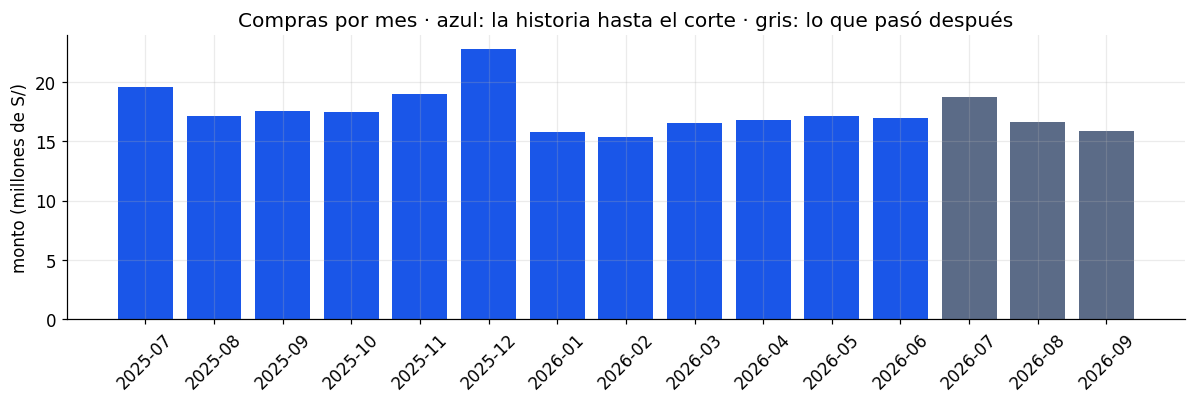

canal
presencial    0.653
online        0.347


In [2]:
# ── DEMOSTRACIÓN A.0 ──────────────────────────────────────────────────
por_mes = tx.groupby(tx["fecha_hora"].dt.to_period("M")).agg(compras=("id_transaccion", "size"), monto=("monto", "sum"))
fig, ax = plt.subplots(figsize=(11, 3.8))
colores = [BLUE if p <= pd.Period("2026-06") else GRAY for p in por_mes.index]
ax.bar(por_mes.index.astype(str), por_mes["monto"] / 1e6, color=colores)
ax.set_ylabel("monto (millones de S/)"); ax.tick_params(axis="x", rotation=45)
ax.set_title("Compras por mes · azul: la historia hasta el corte · gris: lo que pasó después")
plt.tight_layout(); plt.show()
print(tx["canal"].value_counts(normalize=True).round(3).to_string())

### La fecha de corte

Un RFM es una **foto**: se toma en una fecha y solo puede usar lo que pasó **hasta** esa fecha. Hoy la foto es al
**30 de junio de 2026**, la misma fecha de la última foto de la cartera de la Clase 9. Así podemos cruzar con el default de
los tres meses siguientes **sin hacer trampa**.

Los datos llegan hasta septiembre de 2026 a propósito: julio a septiembre es **el futuro** de la foto. No entra al RFM;
lo vamos a usar en el Bloque D para comprobar si los segmentos acertaron.

### Ejercicio A.1 — Separar la historia del futuro

1. `historia`: las compras con `fecha_hora` **hasta el cierre** del 30 de junio de 2026. Cuidado: `fecha_hora` tiene hora,
   así que «menor o igual que `CORTE`» deja fuera casi todo el día 30. Usa `< CORTE + pd.Timedelta(days=1)`.
2. `futuro`: el resto (julio a septiembre de 2026).

In [3]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
historia = tx[tx["fecha_hora"] < CORTE + pd.Timedelta(days=1)]
futuro = tx[tx["fecha_hora"] >= CORTE + pd.Timedelta(days=1)]
print(f"historia: {len(historia):,} compras · futuro: {len(futuro):,} compras".replace(",", " "))

historia: 355 704 compras · futuro: 83 321 compras


In [4]:
# ── VERIFICACIÓN A.1 ──────────────────────────────────────────────────
r = [check("compras en la historia", None if historia is None else len(historia), 355704, tol=0),
     check("compras en el futuro", None if futuro is None else len(futuro), 83321, tol=0),
     check_bool("la última compra de la historia es del 30 de junio",
                historia is not None and historia["fecha_hora"].max().date() == CORTE.date(),
                "¿usaste <= CORTE? Así se pierde casi todo el 30 de junio")]
print()
print("A.1 OK" if all(r) else "Revisa A.1")

[OK] compras en la historia
     tu resultado: 355704.0000   |   esperado: 355704.0000
[OK] compras en el futuro
     tu resultado: 83321.0000   |   esperado: 83321.0000
[OK] la última compra de la historia es del 30 de junio

A.1 OK


### Ejercicio A.2 — La tabla RFM

Una fila por cliente, con índice `id_cliente` y tres columnas:

- `recencia`: días entre la **fecha** de la última compra y `CORTE`. Una compra el mismo 30 de junio da 0.
  (Pista: `(CORTE - ultima.dt.normalize()).dt.days`.)
- `frecuencia`: número de compras en `historia`.
- `monto`: suma de `monto` en `historia`.

**La trampa:** un `groupby` sobre las transacciones **solo ve a los clientes que compraron**. Los que no compraron nada en
el año desaparecen, y son justamente los que más interesan. Parte de la lista `clientes` (los 6 685) y completa a los que no
tienen compras con `frecuencia = 0`, `monto = 0` y `recencia = 366` (más días que la ventana).

In [5]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
agg = historia.groupby("id_cliente").agg(ultima=("fecha_hora", "max"),
                                         frecuencia=("id_transaccion", "size"),
                                         monto=("monto", "sum"))
rfm = agg.reindex(clientes)                       # los 6 685, incluidos los que no compraron
rfm["recencia"] = (CORTE - rfm["ultima"].dt.normalize()).dt.days
rfm = rfm.fillna({"recencia": 366, "frecuencia": 0, "monto": 0})
rfm = rfm[["recencia", "frecuencia", "monto"]].astype({"recencia": int, "frecuencia": int})
rfm.head()

,recencia,frecuencia,monto
id_cliente,,,
102992,13,34,17347.15
105839,1,128,21942.00
105969,116,37,16357.50
107034,2,63,12929.19
103700,19,54,29636.76


In [6]:
# ── VERIFICACIÓN A.2 ──────────────────────────────────────────────────
r = [check("clientes en la tabla", None if rfm is None else len(rfm), 6685, tol=0),
     check("clientes sin ninguna compra", None if rfm is None else (rfm["frecuencia"] == 0).sum(), 320, tol=0),
     check("mediana de la recencia (días)", None if rfm is None else rfm["recencia"].median(), 7, tol=0),
     check("monto total del año (millones de S/)", None if rfm is None else rfm["monto"].sum() / 1e6, 212.0514, tol=0.001)]
print()
print("A.2 OK" if all(r) else "Revisa A.2")

[OK] clientes en la tabla
     tu resultado: 6685.0000   |   esperado: 6685.0000
[OK] clientes sin ninguna compra
     tu resultado: 320.0000   |   esperado: 320.0000
[OK] mediana de la recencia (días)
     tu resultado: 7.0000   |   esperado: 7.0000
[OK] monto total del año (millones de S/)
     tu resultado: 212.0514   |   esperado: 212.0514

A.2 OK


**La mitad de la cartera compró en los últimos 7 días.** Es una cartera muy activa: eso va a importar en el Bloque B.

### Demostración A.3 — ¿Qué pasa si te olvidas de la fecha de corte?

Calculamos la recencia de dos maneras y medimos qué tan bien **separa a los que caen en default** (con el AUC de la
Clase 6: 0.5 es azar, 1 es perfecto):

- **Bien:** con la historia, al 30 de junio.
- **Mal:** con todas las compras, al 30 de septiembre. Es decir, mirando los tres meses en los que se mide el default.

In [7]:
# ── DEMOSTRACIÓN A.3 ──────────────────────────────────────────────────
if rfm is not None:
    fin = pd.Timestamp("2026-09-30")
    ult_todo = tx.groupby("id_cliente")["fecha_hora"].max().reindex(clientes)
    rec_fuga = (fin - ult_todo.dt.normalize()).dt.days.fillna(458)
    y = default.reindex(clientes)
    print(f"AUC de la recencia con la fecha de corte correcta: {roc_auc_score(y, rfm['recencia']):.3f}")
    print(f"AUC de la recencia mirando el futuro:              {roc_auc_score(y, rec_fuga):.3f}")

AUC de la recencia con la fecha de corte correcta: 0.741
AUC de la recencia mirando el futuro:              0.894


La recencia «mal hecha» parece **mucho mejor** (0.89 contra 0.74). No es que sea mejor: un cliente que cae en default tiene
la tarjeta **bloqueada**, así que deja de comprar en julio. Si la recencia mira julio a septiembre, está viendo la respuesta.

> **Fuga de información (leakage).** Es el mismo error de la Clase 6, ahora en una variable de comportamiento. En producción
> nadie tiene los datos del futuro, y el modelo que parecía excelente se cae. **Toda variable se calcula con lo que había a la
> fecha de corte.**

---
# Bloque B · Puntajes y segmentos  ·  30 min

El RFM clásico convierte cada número en un **puntaje de 1 a 5** con **quintiles**: el 20 % con menos compras recibe 1, el
siguiente 20 % recibe 2, y así. En recencia es al revés: **menos días es mejor**, así que los más recientes reciben 5.

Es la misma lógica de las bandas de la Clase 9 (de Muy alto a Muy bajo).

### Ejercicio B.1 — Puntajes F y M por quintiles

Crea `rfm["F"]` y `rfm["M"]` con `pd.qcut(..., 5, labels=[1, 2, 3, 4, 5])`.

**Detalle importante:** la frecuencia es un **conteo** y hay muchos empates (cientos de clientes con exactamente 30 compras).
`pd.qcut` necesita cortes distintos, y con empates falla o arma grupos desiguales. El truco estándar es cortar sobre el
**ranking**: `rfm["frecuencia"].rank(method="first")`, que rompe los empates por orden de aparición. Usa el mismo truco
en el monto. Convierte el resultado a `int`.

In [8]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
def quintil(s):
    return pd.qcut(s.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["F"] = quintil(rfm["frecuencia"])
rfm["M"] = quintil(rfm["monto"])
print(rfm.groupby("F")["frecuencia"].agg(["count", "min", "max"]).to_string())

   count  min  max
F                 
1   1337    0   18
2   1337   18   37
3   1337   37   55
4   1337   55   81
5   1337   81  617


In [9]:
# ── VERIFICACIÓN B.1 ──────────────────────────────────────────────────
tiene = rfm is not None and {"F", "M"} <= set(rfm.columns)
r = [check_bool("cada puntaje de F tiene 1 337 clientes", tiene and set(rfm["F"].value_counts()) == {1337}),
     check("menor frecuencia con F = 5", rfm.loc[rfm["F"] == 5, "frecuencia"].min() if tiene else None, 81, tol=0),
     check("menor monto con M = 5 (S/)", rfm.loc[rfm["M"] == 5, "monto"].min() if tiene else None, 34796.13, tol=0.01),
     check("correlación de Spearman entre F y M", rfm[["frecuencia", "monto"]].corr("spearman").iloc[0, 1] if tiene else None, 0.539, tol=0.005)]
print()
print("B.1 OK" if all(r) else "Revisa B.1")

[OK] cada puntaje de F tiene 1 337 clientes
[OK] menor frecuencia con F = 5
     tu resultado: 81.0000   |   esperado: 81.0000
[OK] menor monto con M = 5 (S/)
     tu resultado: 34796.1300   |   esperado: 34796.1300
[OK] correlación de Spearman entre F y M
     tu resultado: 0.5389   |   esperado: 0.5390

B.1 OK


F y M tienen una correlación de **0.54**: el que compra seguido suele gastar más, pero no siempre (un cliente que compra
pasajes dos veces al año gasta mucho con poca frecuencia). Por eso las juntamos en un solo eje de **valor**, sin perder
ninguna de las dos.

### Demostración B.2 — Los quintiles no sirven para la recencia de esta cartera

Cortes de los quintiles de recencia (días): [  0.   1.   4.  12.  55. 366.]

Con quintiles, un cliente que compró hace 13 días recibiría R = 2 (de 5),
el mismo puntaje bajo que uno que no compra hace casi dos meses.


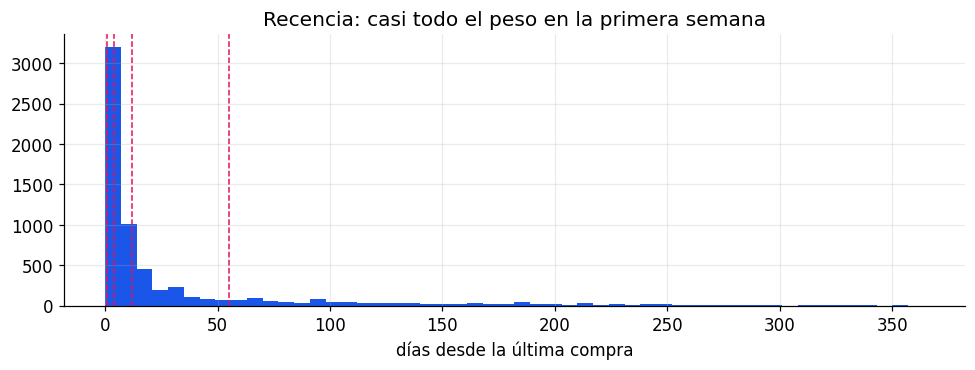

In [10]:
# ── DEMOSTRACIÓN B.2 ──────────────────────────────────────────────────
if rfm is not None:
    cortes = rfm["recencia"].quantile([0, .2, .4, .6, .8, 1]).values
    print("Cortes de los quintiles de recencia (días):", cortes)
    print("\nCon quintiles, un cliente que compró hace 13 días recibiría R = 2 (de 5),")
    print("el mismo puntaje bajo que uno que no compra hace casi dos meses.")
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.hist(rfm["recencia"], bins=np.arange(0, 370, 7), color=BLUE)
    for c in cortes[1:-1]:
        ax.axvline(c, color=MAG, ls="--", lw=1)
    ax.set_xlabel("días desde la última compra"); ax.set_title("Recencia: casi todo el peso en la primera semana")
    plt.tight_layout(); plt.show()

Los quintiles cortan en **1, 4, 12 y 55 días**. Tres de los cinco puntajes separan a clientes que compraron **en el mismo
mes**: para el negocio son igual de activos. Los quintiles funcionan cuando el dato está repartido; aquí la mitad de la
cartera compró la última semana.

La solución habitual en banca es usar **cortes de negocio** para R y dejar los quintiles para F y M:

| R | Días desde la última compra | Lectura |
|---|---|---|
| 5 | 0 a 7 | compró esta semana |
| 4 | 8 a 30 | compró este mes |
| 3 | 31 a 60 | lleva un mes sin comprar |
| 2 | 61 a 120 | dos a cuatro meses sin comprar |
| 1 | más de 120, o ninguna compra | inactivo |

### Ejercicio B.3 — Puntaje R con cortes de negocio

Crea `rfm["R"]` con `pd.cut` y los bordes `[-1, 7, 30, 60, 120, 10**6]`. Ojo con el orden de las etiquetas: el primer
tramo (0 a 7 días) es el **5**. Convierte a `int`. Después crea `rfm["FM"]`, el **promedio** de F y M.

In [11]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
rfm["R"] = pd.cut(rfm["recencia"], [-1, 7, 30, 60, 120, 10**6], labels=[5, 4, 3, 2, 1]).astype(int)
rfm["FM"] = (rfm["F"] + rfm["M"]) / 2
print(rfm["R"].value_counts().sort_index().to_string())

R
1     818
2     484
3     436
4    1539
5    3408


In [12]:
# ── VERIFICACIÓN B.3 ──────────────────────────────────────────────────
tiene = rfm is not None and {"R", "FM"} <= set(rfm.columns)
cuenta = rfm["R"].value_counts() if tiene else None
r = [check("clientes con R = 5", None if cuenta is None else cuenta.get(5), 3408, tol=0),
     check("clientes con R = 1", None if cuenta is None else cuenta.get(1), 818, tol=0),
     check("FM promedio", rfm["FM"].mean() if tiene else None, 3.0, tol=1e-9)]
print()
print("B.3 OK" if all(r) else "Revisa B.3")

[OK] clientes con R = 5
     tu resultado: 3408.0000   |   esperado: 3408.0000
[OK] clientes con R = 1
     tu resultado: 818.0000   |   esperado: 818.0000
[OK] FM promedio
     tu resultado: 3.0000   |   esperado: 3.0000

B.3 OK


### Ejercicio B.4 — El mapa de segmentos

Con dos ejes, **R** (qué tan reciente) y **FM** (cuánto vale), cada cliente cae en un segmento. Las reglas se revisan **en
este orden** y gana la primera que se cumple:

| # | Segmento | Regla | Quiénes son |
|---|---|---|---|
| 1 | **Campeones** | R = 5 y FM ≥ 4.5 | compran esta semana, mucho y seguido |
| 2 | **Leales** | R ≥ 4 y FM ≥ 3.5 | activos y de alto valor |
| 3 | **Potenciales** | R ≥ 4 y FM ≥ 2.5 | activos, valor medio: se pueden desarrollar |
| 4 | **Ocasionales** | R ≥ 4 (y FM < 2.5) | compran, pero poco |
| 5 | **En riesgo** | FM ≥ 3 (y R ≤ 3) | **valían** y dejaron de comprar |
| 6 | **Enfriándose** | R = 3 (y FM < 3) | valor bajo y un mes sin comprar |
| 7 | **Perdidos** | el resto | valor bajo y meses sin comprar |

Completa la función `segmentar(r, fm)` y crea `rfm["segmento"]`.

In [13]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
def segmentar(r, fm):
    if r == 5 and fm >= 4.5:
        return "Campeones"
    if r >= 4 and fm >= 3.5:
        return "Leales"
    if r >= 4 and fm >= 2.5:
        return "Potenciales"
    if r >= 4:
        return "Ocasionales"
    if fm >= 3:
        return "En riesgo"
    if r == 3:
        return "Enfriándose"
    return "Perdidos"

rfm["segmento"] = [segmentar(r, fm) for r, fm in zip(rfm["R"], rfm["FM"])]
print(rfm["segmento"].value_counts().to_string())

segmento
Leales         1959
Potenciales    1254
Perdidos       1038
Campeones       896
Ocasionales     838
En riesgo       436
Enfriándose     264


In [14]:
# ── VERIFICACIÓN B.4 ──────────────────────────────────────────────────
tam = rfm["segmento"].value_counts() if rfm is not None and "segmento" in rfm else None
def t(nombre):
    return None if tam is None or nombre not in tam.index else tam[nombre]
r = [check_bool("hay 7 segmentos y ningún cliente sin segmento", tam is not None and len(tam) == 7 and rfm["segmento"].notna().all(),
                "¿completaste las cinco reglas? ¿la última devuelve 'Perdidos'?"),
     check("Campeones", t("Campeones"), 896, tol=0),
     check("En riesgo", t("En riesgo"), 436, tol=0),
     check("Perdidos", t("Perdidos"), 1038, tol=0)]
print()
print("B.4 OK" if all(r) else "Revisa B.4")

[OK] hay 7 segmentos y ningún cliente sin segmento
[OK] Campeones
     tu resultado: 896.0000   |   esperado: 896.0000
[OK] En riesgo
     tu resultado: 436.0000   |   esperado: 436.0000
[OK] Perdidos
     tu resultado: 1038.0000   |   esperado: 1038.0000

B.4 OK


### Demostración B.5 — Quiénes son los mejores: el mapa y la concentración del gasto

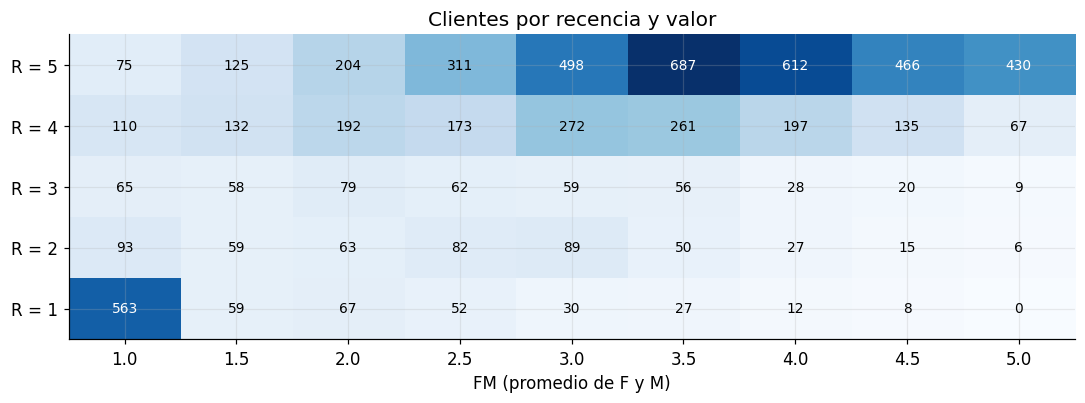

             clientes  % clientes  % del gasto
segmento                                      
Campeones         896        13.4         45.8
Leales           1959        29.3         32.7
Potenciales      1254        18.8          8.2
En riesgo         436         6.5          7.6
Ocasionales       838        12.5          2.7
Perdidos         1038        15.5          2.0
Enfriándose       264         3.9          1.0


In [15]:
# ── DEMOSTRACIÓN B.5 ──────────────────────────────────────────────────
if rfm is not None and "segmento" in rfm:
    mapa = pd.crosstab(rfm["R"], rfm["FM"]).sort_index(ascending=False)
    fig, ax = plt.subplots(figsize=(10, 3.8))
    im = ax.imshow(mapa.values, cmap="Blues", aspect="auto")
    ax.set_xticks(range(mapa.shape[1])); ax.set_xticklabels(mapa.columns)
    ax.set_yticks(range(mapa.shape[0])); ax.set_yticklabels([f"R = {r}" for r in mapa.index])
    for (f, c), v in np.ndenumerate(mapa.values):
        ax.text(c, f, v, ha="center", va="center", fontsize=9, color="white" if v > 400 else "black")
    ax.set_xlabel("FM (promedio de F y M)"); ax.set_title("Clientes por recencia y valor")
    plt.tight_layout(); plt.show()

    valor = rfm.groupby("segmento").agg(clientes=("monto", "size"), monto=("monto", "sum"))
    valor["% clientes"] = (valor["clientes"] / valor["clientes"].sum() * 100).round(1)
    valor["% del gasto"] = (valor["monto"] / valor["monto"].sum() * 100).round(1)
    print(valor.sort_values("% del gasto", ascending=False)[["clientes", "% clientes", "% del gasto"]].to_string())

**Campeones y Leales son el 43 % de los clientes y hacen el 78 % del gasto.** Solo los Campeones (13 %) hacen el 46 %.
Es la regla de Pareto que aparece en casi toda cartera: perder un Campeón cuesta lo que perder a decenas de Ocasionales.

En el otro extremo, **Perdidos** son el 16 % de los clientes y apenas el 2 % del gasto.

---
# Bloque C · K-Means sobre RFM  ·  25 min

Las reglas del Bloque B las escribimos **nosotros**. ¿Qué segmentos encuentran **los datos**, si dejamos que K-Means
agrupe con las mismas tres variables? Es lo mismo de la Clase 10, con dos cuidados:

1. **Sin los 320 clientes sin compras.** Ya sabemos qué son; si entran, K-Means gasta un grupo en separarlos (con
   `log1p(0) = 0` quedan aislados) y la silueta premia esa separación obvia.
2. **Logaritmo y escalado.** Los tres son montos y conteos sesgados.

### Ejercicio C.1 — Elegir k

1. `activos`: las filas de `rfm` con `frecuencia > 0`.
2. `Xs`: `np.log1p` de `recencia`, `frecuencia` y `monto` de `activos`, escalado con `StandardScaler`.
3. `sil`: una `pd.Series` con la silueta de K-Means para k de 2 a 8 (índice = k). Usa `n_init=10, random_state=SEED`.

In [16]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
activos = rfm[rfm["frecuencia"] > 0].copy()
Xs = StandardScaler().fit_transform(np.log1p(activos[["recencia", "frecuencia", "monto"]]))
sil = pd.Series({k: silhouette_score(Xs, KMeans(k, n_init=10, random_state=SEED).fit_predict(Xs)) for k in range(2, 9)})
print(sil.round(3).to_string())

2    0.398
3    0.342
4    0.322
5    0.287
6    0.293
7    0.276
8    0.272


[OK] clientes activos
     tu resultado: 6365.0000   |   esperado: 6365.0000
[OK] silueta con k = 2
     tu resultado: 0.3985   |   esperado: 0.3985
[OK] silueta con k = 4
     tu resultado: 0.3216   |   esperado: 0.3216

C.1 OK


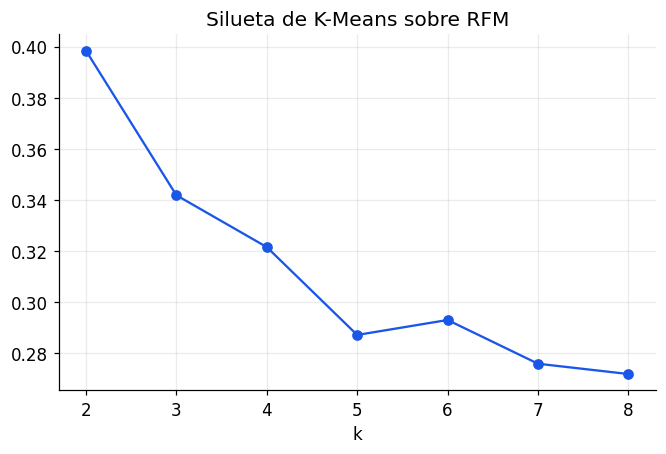

In [17]:
# ── VERIFICACIÓN C.1 ──────────────────────────────────────────────────
r = [check("clientes activos", None if activos is None else len(activos), 6365, tol=0),
     check("silueta con k = 2", None if sil is None else sil.get(2), 0.3985, tol=0.01),
     check("silueta con k = 4", None if sil is None else sil.get(4), 0.3216, tol=0.01)]
print()
print("C.1 OK" if all(r) else "Revisa C.1")
if sil is not None:
    sil.plot(marker="o", color=BLUE, title="Silueta de K-Means sobre RFM"); plt.xlabel("k"); plt.show()

La silueta prefiere **k = 2**, pero dos grupos («compran mucho» y «compran poco») no le sirven a nadie. Como en la Clase 10,
la métrica propone y el negocio decide: tomamos **k = 4**, el más chico que distingue a los que se están yendo.

### Ejercicio C.2 — Cuatro clusters con nombre

1. `km4`: K-Means con 4 grupos sobre `Xs` (`n_init=10, random_state=SEED`). Guarda las etiquetas en `activos["cluster"]`.
2. `perfil`: la **mediana** de `recencia`, `frecuencia` y `monto` por cluster, más la columna `clientes`.
3. Pon nombres con reglas sobre el perfil, en este orden: **Alto valor** (el de mayor monto), **Dormidos** (de los que
   quedan, el de mayor recencia), **Enfriándose** (de los que quedan, el de mayor recencia) y **Activos** (el último).
   Guarda el nombre en `activos["cluster_nombre"]`.

In [18]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
km4 = KMeans(4, n_init=10, random_state=SEED).fit(Xs)
activos["cluster"] = km4.labels_
perfil = activos.groupby("cluster")[["recencia", "frecuencia", "monto"]].median()
perfil["clientes"] = activos["cluster"].value_counts()

nombres, libres = {}, list(perfil.index)
for nombre, var in [("Alto valor", "monto"), ("Dormidos", "recencia"), ("Enfriándose", "recencia")]:
    c = perfil.loc[libres, var].idxmax()
    nombres[c] = nombre
    libres.remove(c)
nombres[libres[0]] = "Activos"
activos["cluster_nombre"] = activos["cluster"].map(nombres)
perfil.rename(index=nombres).round(0)

,recencia,frecuencia,monto,clientes
cluster,,,,
Enfriándose,33.0,26.0,10458.0,1998
Alto valor,3.0,77.0,99607.0,1164
Activos,3.0,58.0,14644.0,2862
Dormidos,174.0,2.0,661.0,341


In [19]:
# ── VERIFICACIÓN C.2 ──────────────────────────────────────────────────
tam = activos["cluster_nombre"].value_counts() if activos is not None and "cluster_nombre" in activos else None
def t(nombre):
    return None if tam is None or nombre not in tam.index else tam[nombre]
r = [check("clientes en Alto valor", t("Alto valor"), 1164, tol=30),
     check("clientes en Dormidos", t("Dormidos"), 341, tol=30),
     check("clientes en Enfriándose", t("Enfriándose"), 1998, tol=40),
     check("clientes en Activos", t("Activos"), 2862, tol=40)]
print()
print("C.2 OK" if all(r) else "Revisa C.2")

[OK] clientes en Alto valor
     tu resultado: 1164.0000   |   esperado: 1164.0000
[OK] clientes en Dormidos
     tu resultado: 341.0000   |   esperado: 341.0000
[OK] clientes en Enfriándose
     tu resultado: 1998.0000   |   esperado: 1998.0000
[OK] clientes en Activos
     tu resultado: 2862.0000   |   esperado: 2862.0000

C.2 OK


### Demostración C.3 — ¿Reglas o clusters?

In [20]:
# ── DEMOSTRACIÓN C.3 ──────────────────────────────────────────────────
if activos is not None and "cluster_nombre" in activos:
    orden = ["Campeones", "Leales", "Potenciales", "Ocasionales", "En riesgo", "Enfriándose", "Perdidos"]
    cruce = pd.crosstab(activos["segmento"], activos["cluster_nombre"]).reindex(orden)
    print(cruce[["Alto valor", "Activos", "Enfriándose", "Dormidos"]].to_string())
    print(f"\nARI entre reglas y clusters: {adjusted_rand_score(activos['segmento'], activos['cluster']):.3f}")

cluster_nombre  Alto valor  Activos  Enfriándose  Dormidos
segmento                                                  
Campeones              711      185            0         0
Leales                 401     1440          118         0
Potenciales              0      936          318         0
Ocasionales              0      299          486        53
En riesgo               52        2          382         0
Enfriándose              0        0          241        23
Perdidos                 0        0          453       265

ARI entre reglas y clusters: 0.245


Coinciden en los **extremos**: todos los Campeones caen en Alto valor o Activos, y casi todos los En riesgo en Enfriándose.
En el medio no: K-Means mete en **Enfriándose** a clientes que las reglas reparten entre cinco segmentos. El ARI de **0.25**
lo resume: se parecen, pero no son lo mismo.

| | Reglas RFM | K-Means sobre RFM |
|---|---|---|
| Quién define los grupos | el negocio | los datos |
| Se explica en una reunión | sí, en una frase | hay que mostrar el perfil |
| Mes a mes | el mismo cliente con los mismos números cae en el mismo segmento | los centros se mueven y los grupos cambian |
| Para qué sirve más | campañas y tableros recurrentes | **descubrir** cortes que las reglas no ven |

En la práctica se usan **las dos**: el clustering para explorar y proponer cortes, y las reglas para operar todos los meses.

---
# Bloque D · Validar con el futuro y decidir  ·  30 min

Un segmento vale si **predice algo** que el negocio no sabía. Tenemos dos cosas que pasaron **después** de la foto:

- `futuro`: si el cliente volvió a comprar entre julio y septiembre.
- `default`: si cayó en default en esos tres meses (de la cartera de la Clase 9).

### Ejercicio D.1 — La tabla de validación

1. `rfm["compro_jul_sep"]`: 1 si el cliente tiene al menos una compra en `futuro`, 0 si no.
2. `rfm["default_3m"]`: el default de cada cliente (la serie `default`, alineada por `id_cliente`).
3. `validacion`: por segmento, `clientes`, `compro_jul_sep` (promedio) y `default_3m` (promedio), ordenada de menor a mayor
   `compro_jul_sep`.

In [21]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
rfm["compro_jul_sep"] = rfm.index.isin(futuro["id_cliente"].unique()).astype(int)
rfm["default_3m"] = default.reindex(rfm.index)
validacion = (rfm.groupby("segmento")
              .agg(clientes=("R", "size"), compro_jul_sep=("compro_jul_sep", "mean"), default_3m=("default_3m", "mean"))
              .sort_values("compro_jul_sep"))
validacion.round(3)

,clientes,compro_jul_sep,default_3m
segmento,,,
Perdidos,1038,0.204,0.228
En riesgo,436,0.452,0.319
Enfriándose,264,0.636,0.155
Ocasionales,838,0.890,0.032
Potenciales,1254,0.919,0.054
Leales,1959,0.934,0.038
Campeones,896,0.973,0.020


In [22]:
# ── VERIFICACIÓN D.1 ──────────────────────────────────────────────────
def v(seg, col):
    return None if validacion is None or seg not in validacion.index else validacion.loc[seg, col]
r = [check("compraron en jul-sep: Campeones", v("Campeones", "compro_jul_sep"), 0.973, tol=0.002),
     check("compraron en jul-sep: Perdidos", v("Perdidos", "compro_jul_sep"), 0.204, tol=0.002),
     check("default: En riesgo", v("En riesgo", "default_3m"), 0.319, tol=0.002),
     check("default: toda la cartera", None if validacion is None else rfm["default_3m"].mean(), 0.0905, tol=0.001)]
print()
print("D.1 OK" if all(r) else "Revisa D.1")

[OK] compraron en jul-sep: Campeones
     tu resultado: 0.9732   |   esperado: 0.9730
[OK] compraron en jul-sep: Perdidos
     tu resultado: 0.2042   |   esperado: 0.2040
[OK] default: En riesgo
     tu resultado: 0.3188   |   esperado: 0.3190
[OK] default: toda la cartera
     tu resultado: 0.0905   |   esperado: 0.0905

D.1 OK


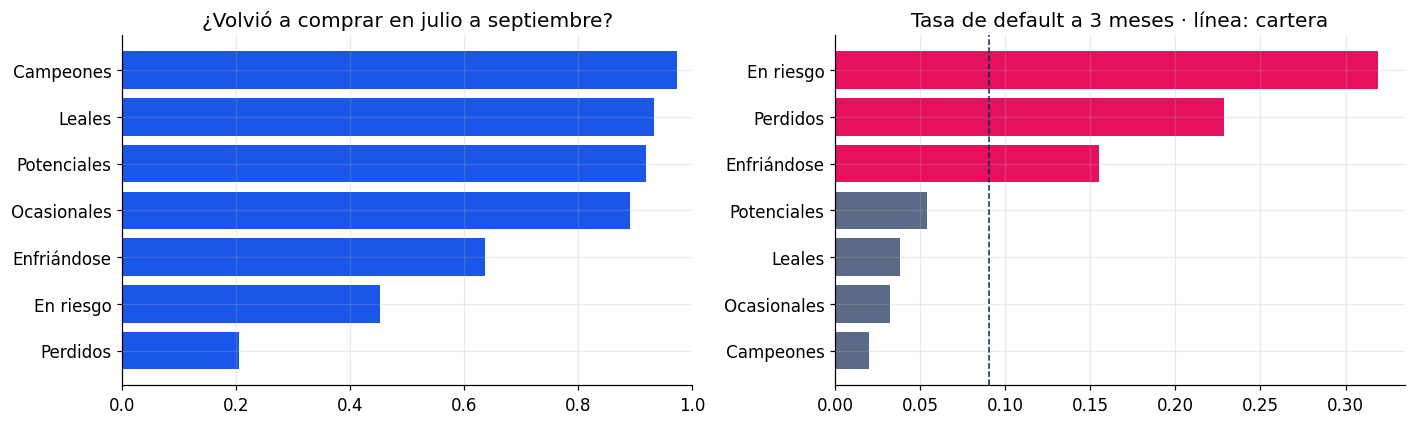

In [23]:
# ── DEMOSTRACIÓN D.2 ──────────────────────────────────────────────────
if validacion is not None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    vv = validacion.sort_values("compro_jul_sep")
    axes[0].barh(vv.index, vv["compro_jul_sep"], color=BLUE); axes[0].set_xlim(0, 1)
    axes[0].set_title("¿Volvió a comprar en julio a septiembre?")
    vd = validacion.sort_values("default_3m")
    axes[1].barh(vd.index, vd["default_3m"], color=[MAG if x > 0.15 else GRAY for x in vd["default_3m"]])
    axes[1].axvline(rfm["default_3m"].mean(), color=NAVY, ls="--", lw=1)
    axes[1].set_title("Tasa de default a 3 meses · línea: cartera")
    plt.tight_layout(); plt.show()

Dos lecturas, y la segunda es la importante:

1. **El RFM predice la actividad.** El 97 % de los Campeones volvió a comprar; de los Perdidos, solo el 20 %, y de los
   En riesgo, el 45 %. Con tres números y unas reglas se anticipa quién se va.
2. **En riesgo no siempre significa «se fue a la competencia».** Ese segmento tiene una tasa de default de **31.9 %**, 3.5
   veces la cartera. Muchos dejaron de comprar porque **coparon la línea**: no pueden comprar, y después no pueden pagar.

> **Por eso el RFM no se usa solo.** Si el área comercial lanza una campaña de «te extrañamos, aquí tienes más línea» a
> todo En riesgo, le está ofreciendo crédito a uno de cada tres clientes que va a caer en default. Antes de actuar, se
> cruza con el **score de riesgo** de la Clase 9.

### Qué hacer con cada segmento

| Segmento | % clientes | % gasto | Acción |
|---|---|---|---|
| Campeones | 13 % | 46 % | Cuidarlos: beneficios, atención preferente. **No** saturarlos de ofertas. |
| Leales | 29 % | 33 % | Programas de puntos, subir a Campeones con ofertas de categorías nuevas. |
| Potenciales | 19 % | 8 % | Desarrollar: promociones en los rubros que ya usan. |
| Ocasionales | 13 % | 3 % | Activación de bajo costo (app, cashback en la primera compra del mes). |
| En riesgo | 7 % | 8 % | **Primero el score.** Bajo riesgo: retención; alto riesgo: cobranza preventiva. |
| Enfriándose | 4 % | 1 % | Recordatorio barato antes de que pasen a Perdidos. |
| Perdidos | 16 % | 2 % | No gastar campaña en todos; reactivación solo a los de mejor score. |

### Puente al trabajo final

Las variables RFM son de las mejores para predecir **churn**: la recencia sola ya separa a los que se van. En el trabajo
final pueden construirlas desde `transacciones_mensual.csv`, **a la fecha de corte de cada periodo** (sin mirar el futuro,
como en la Demostración A.3).

---
# Cierre

### Los números del día

| | |
|---|---|
| Compras en la historia | 355 704 (julio 2025 a junio 2026), de 6 685 clientes |
| Fecha de corte | 30 de junio de 2026 |
| AUC de la recencia | 0.74 bien calculada · 0.89 con fuga de información |
| Concentración | Campeones + Leales: 43 % de clientes, 78 % del gasto |
| Volvieron a comprar | 97 % de los Campeones · 20 % de los Perdidos |
| Default | 31.9 % en En riesgo · 2.0 % en Campeones · cartera 9.1 % |

### Checklist de salida

- [ ] Construyo la tabla RFM desde el transaccional, **sin perder** a los clientes sin compras.
- [ ] Calculo todo a una **fecha de corte** y sé explicar por qué mirar el futuro infla el resultado.
- [ ] Uso quintiles con `rank(method="first")` y sé cuándo los quintiles no sirven (recencia muy concentrada).
- [ ] Armo un mapa de segmentos con reglas en orden y lo leo con el negocio (Pareto del gasto).
- [ ] Comparo reglas con K-Means y sé para qué sirve cada uno.
- [ ] Valido los segmentos con lo que pasó después y los cruzo con el riesgo antes de actuar.

### Preguntas tipo examen

**1.** Un analista calcula el RFM con `tx.groupby("id_cliente")` y reporta 6 365 clientes. La base tiene 6 685. ¿Qué pasó?

> **Respuesta.** El `groupby` sobre transacciones solo ve a los clientes que compraron. Los 320 sin compras en la ventana
> desaparecieron, y son justamente los inactivos. Hay que partir de la lista de clientes y completar con 0 compras.

**2.** La recencia calculada con todos los datos disponibles predice el default con AUC 0.89, y la calculada al corte con
0.74. ¿Cuál se usa?

> **Respuesta.** La de 0.74. La otra mira los meses en que se mide el default (cuando la tarjeta ya está bloqueada): es fuga
> de información. En producción no existe y el modelo se cae.

**3.** ¿Por qué se usa `rank(method="first")` antes de `pd.qcut` con la frecuencia?

> **Respuesta.** Porque la frecuencia es un conteo con muchos empates. Sin el ranking, `qcut` puede fallar por cortes
> repetidos o armar quintiles de tamaños muy distintos. El ranking rompe los empates y deja cinco grupos iguales.

**4.** El área comercial quiere mandar una oferta de aumento de línea a todo el segmento En riesgo. ¿Qué le dices?

> **Respuesta.** Que primero cruce con el score de riesgo: ese segmento tiene 31.9 % de default. Muchos dejaron de comprar
> porque coparon la línea. Ofrecerles más crédito aumenta la pérdida; a esos les corresponde cobranza preventiva.

**5.** K-Means sobre RFM y las reglas tienen un ARI de 0.25. ¿Alguno está mal?

> **Respuesta.** No necesariamente. Responden cosas distintas: las reglas son cortes de negocio fijos y explicables; K-Means
> agrupa por cercanía en los datos. Coinciden en los extremos y difieren en el medio. Se usa K-Means para explorar y las
> reglas para operar.

### Lo que sigue

Próxima clase: **puesta en producción e introducción a Databricks**. Y con este mismo transaccional, más adelante:
**fraude** (detección de anomalías) y **grafos** (quién está conectado con quién).